# Data Engineering & Visualization – Milestone 1
## Member 2 – Transportation Dataset (SIRTA): Overview, EDA & Pre-Integration Cleaning

**Course:** Data Engineering and Visualization, Winter 2026 – GIU
**Team member:** Member 2 (Mariam) – Transportation dataset
**Output of this notebook:** `transport_clean_row_level.csv` (clean crash records) and `transport_clean.csv` (aggregated to **ZIP code × year**, ready for Member 3 to integrate with the housing dataset).

**Contents**
1. Dataset overview and reasoning for selection
2. Loading the data (with justification for any sampling)
3. Exploratory Data Analysis (EDA)
4. Pre-integration cleaning (missing values, duplicates, inconsistencies, formats, outliers)
5. Validation of cleaning (before vs. after)
6. Aggregation to the integration level (ZIP code × year) – the data contract
7. Research questions and visualizations (Member 2)
8. Prompts used, dataset links, and contribution statement

## 1. Dataset overview and reasoning for selection

| Item | Value |
|---|---|
| Dataset | **Serious Injury Response, Tracking & Analysis Program (SIRTA)** – catalog ID **T4** |
| Domain | Transportation |
| Publisher | NYC Department of Transportation (DOT) |
| Dataset ID | `xeqp-qz8h` |
| Link | https://data.cityofnewyork.us/Transportation/Serious-Injury-Response-Tracking-Analysis-Program-/xeqp-qz8h |
| Data dictionary | `SIRTA_Data_Dictionary.xlsx` (provided by the course) |
| Unit of analysis (row) | One serious vehicular crash that DOT analyzed and reported at a specific location |
| Rows / columns | 13,754 rows x 23 columns in the downloaded CSV (requirement: at least 9 columns) |
| Period covered | 01/01/2022 - 12/31/2024 (date format MM/DD/YYYY in the CSV export) |
| Temporal attributes | `Crash Date` (YYYY-MM-DD), `Crash Time` (HH:MM) |
| Geographic attributes | `Crash Borough`, `ZipCode`, `Latitude`/`Longitude`, `Community Board`, `Council District`, `NTA 2020`, `Census Tract 2020`, `BIN`, `BBL`, `Crash Police Precinct` |
| Update frequency | Quarterly publication (Local Law 49 of 2021) |

**Columns (from the data dictionary / portal):** Collision ID, Crash Date, Crash Time, Crash Police Precinct, Crash Borough, Total Non-Severe Injuries, Total Severe Injuries, Total Fatalities, Latitude, Longitude, On Street, Cross Street, Address, Highway Reference Marker, ZipCode, Similar Fatalities & Severe Injuries (3Y Lookback), Similar Fatalities & All Injuries (3Y Lookback), Community Board, Council District, BIN, BBL, Census Tract 2020, NTA 2020.

**Why this dataset?**
- It is **in the course catalog (T4)**, so no extra feasibility check is required.
- It has **ZIP code, borough and a crash date**, which are exactly the attributes needed to link it to housing data (permits / job filings) at **ZIP code × year** level.
- It carries **severity information** (severe injuries, fatalities), so we can ask richer questions than simple counts, e.g. whether street danger changes around areas of new residential development.

**Known issues (from the data dictionary, to be verified in the EDA):**
- Data comes directly from NYPD's FORMS system; **blank values mean the data was not recorded**, not zero.
- Only crashes classified as **severe ("A" injuries)** by the NYS DMV formula are included, so this is **not all crashes** – conclusions concern *serious* crashes only.
- Severity classification can lag by more than a year, so the most recent period may be incomplete.

**Granularity / aggregation plan.** The housing dataset has building-level records, while SIRTA has crash-level records. Neither will be joined record-to-record. Both are aggregated to **ZIP code × year** (a common geographic and temporal level that both datasets share). ZIP is fine-grained enough to see neighborhood patterns and coarse enough that each cell contains enough crashes/filings to be meaningful.

## 2. Loading and reproducibility
Use an explicit raw cache when present. Otherwise download the complete 2022-2025 window in stable pages; verify the row count before saving. No hidden fallback, arbitrary sample or partial 2026 year is used. Network failures remain visible. Delete the cache for an intentional refresh; its JSON sidecar records the source/time/count.

SIRTA covers serious-injury/fatal crashes, not all road collisions. The live API schema and crash severity may be revised.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "members").is_dir(), "Run from the repository root or notebooks directory."
CLEAN_DIR = ROOT / "data" / "clean"
RAW_DIR = ROOT / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "members" / "member1_housing"))
sys.path.insert(0, str(ROOT / "members" / "member3_integration"))
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.max_columns", 50)

import io
import json
import ssl
import re
import urllib.request
from urllib.parse import urlencode
import truststore
from sklearn.neighbors import NearestNeighbors
TRANSPORT_ID = "xeqp-qz8h"
API_URL = "https://data.cityofnewyork.us/resource/{}.csv"
LOCAL_CSV = RAW_DIR / "xeqp-qz8h.csv"
YEAR_MIN, YEAR_MAX = 2022, 2025
OUTPUT_ROW_LEVEL = CLEAN_DIR / "transport_clean_row_level.csv"
OUTPUT_AGGREGATED = CLEAN_DIR / "transport_clean.csv"

Inspect the outputs and validation checks for the preceding preparation step.

In [2]:
def load_sirta():
    if LOCAL_CSV.exists():
        print(f"Reading explicit raw cache: {LOCAL_CSV}")
        return pd.read_csv(LOCAL_CSV, low_memory=False)
    where = "crash_date >= '2022-01-01T00:00:00' AND crash_date < '2026-01-01T00:00:00'"
    def fetch(params):
        url = API_URL.format(TRANSPORT_ID) + "?" + urlencode(params)
        with urllib.request.urlopen(url, timeout=180, context=truststore.SSLContext(ssl.PROTOCOL_TLS_CLIENT)) as response:
            return pd.read_csv(io.BytesIO(response.read()), low_memory=False)
    expected = int(fetch({"$select": "count(*)", "$where": where}).iloc[0, 0])
    pages = []
    for offset in range(0, expected + 1, 50000):
        page = fetch({"$where": where, "$order": ":id", "$limit": 50000, "$offset": offset})
        pages.append(page)
        if len(page) < 50000:
            break
    frame = pd.concat(pages, ignore_index=True)
    assert len(frame) == expected, "Source changed while paging; retry before using the data."
    frame.to_csv(LOCAL_CSV, index=False)
    LOCAL_CSV.with_suffix(".json").write_text(json.dumps({
        "source": API_URL.format(TRANSPORT_ID), "where": where, "rows": len(frame),
        "downloaded_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    }, indent=2), encoding="utf-8")
    print(f"Downloaded {len(frame):,} rows, saved {LOCAL_CSV}")
    return frame

df_raw = load_sirta()
df = df_raw.copy()
display(df.head())

Reading explicit raw cache: C:\Users\t-pnassef\OneDrive - Microsoft\Desktop\nyc-housing-transport\data\raw\xeqp-qz8h.csv


,open_data_crash_id,crash_date,crash_time,crash_police_precinct,crash_borough,total_non_severe_injuries,total_severe_injuries,total_fatalities,latitude,longitude,on_street,cross_street,address,highway_reference_marker,zipcode,similar_fatalities_severe,similar_fatalities_all,community_board,council_district,bin,bbl,census_tract_2020_,neighborhood_tabulation_area_nta_2020_
0,4492364,2022-01-01T00:00:00.000,01:28,46,Bronx,1,1,0,40.858707,-73.90370,JEROME AVENUE,EAST 183 STREET,NaN,NaN,NaN,0.0,1,NaN,NaN,NaN,NaN,NaN,NaN
1,4491159,2022-01-01T00:00:00.000,04:33,46,Bronx,0,1,0,NaN,NaN,JEROME AVENUE,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,4491487,2022-01-01T00:00:00.000,05:55,47,Bronx,0,1,0,40.871550,-73.86428,NaN,NaN,3207 WALLACE AVENUE,NaN,NaN,0.0,0,212.0,12.0,2056281.0,2.045980e+09,372.0,BX1201
3,4491223,2022-01-01T00:00:00.000,10:42,43,Bronx,0,1,0,40.823673,-73.87233,BRONX RIVER PARKWAY,NaN,NaN,907HX1M11001,NaN,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,4491418,2022-01-01T00:00:00.000,20:55,49,Bronx,0,1,0,40.863945,-73.86452,BOSTON ROAD,WALLACE AVENUE,NaN,NaN,NaN,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN


Standardize the downloaded schema before selecting source columns.

In [3]:
def standardize_column_names(frame):
    """Lowercase snake_case names so the API and the portal CSV export look identical."""
    frame = frame.copy()
    frame.columns = (frame.columns.str.strip().str.lower()
                     .str.replace(r"[^0-9a-z]+", "_", regex=True).str.strip("_"))
    return frame

df = standardize_column_names(df)
print(df.columns.tolist())

['open_data_crash_id', 'crash_date', 'crash_time', 'crash_police_precinct', 'crash_borough', 'total_non_severe_injuries', 'total_severe_injuries', 'total_fatalities', 'latitude', 'longitude', 'on_street', 'cross_street', 'address', 'highway_reference_marker', 'zipcode', 'similar_fatalities_severe', 'similar_fatalities_all', 'community_board', 'council_district', 'bin', 'bbl', 'census_tract_2020', 'neighborhood_tabulation_area_nta_2020']


Resolve the source column names and parse source date formats explicitly.

In [4]:
def find_column(frame, *keywords):
    """Return the first column whose name contains ALL keywords (robust to API/CSV naming differences)."""
    for column in frame.columns:
        if all(keyword in column for keyword in keywords):
            return column
    raise KeyError(f"No column contains {keywords}. Available: {frame.columns.tolist()}")

def parse_crash_dates(series):
    """Parse dates from either the portal CSV (MM/DD/YYYY) or the API (ISO timestamp)."""
    parsed = pd.to_datetime(series, format="%m/%d/%Y", errors="coerce")
    leftover = parsed.isna() & series.notna()
    if leftover.any():
        parsed[leftover] = pd.to_datetime(series[leftover], errors="coerce")
    return parsed

# Map the logical names we use below to the real column names in the downloaded file.
COL = {
    "collision_id": next(c for c in df.columns if "collision" in c or c.endswith("crash_id")),   # portal CSV: collision_id | API: open_data_crash_id
    "crash_date":   find_column(df, "crash", "date"),
    "crash_time":   find_column(df, "crash", "time"),
    "precinct":     find_column(df, "precinct"),
    "borough":      find_column(df, "borough") if any("borough" in c and "block" not in c for c in df.columns) else None,
    "non_severe":   find_column(df, "non", "severe"),
    "fatalities":   find_column(df, "fatalit") if not any(c.startswith("total_fatalit") for c in df.columns) else "total_fatalities",
    "latitude":     find_column(df, "latitude"),
    "longitude":    find_column(df, "longitude"),
    "zip":          find_column(df, "zip"),
}
# 'total_severe_injuries' must not be confused with 'total_non_severe_injuries'
COL["severe"] = next(c for c in df.columns if "severe" in c and "non" not in c and c.startswith("total"))
COL["borough"] = next(c for c in df.columns if "borough" in c and "block" not in c)
COL["fatalities"] = next(c for c in df.columns if c.startswith("total_fatalit"))
print(COL)

{'collision_id': 'open_data_crash_id', 'crash_date': 'crash_date', 'crash_time': 'crash_time', 'precinct': 'crash_police_precinct', 'borough': 'crash_borough', 'non_severe': 'total_non_severe_injuries', 'fatalities': 'total_fatalities', 'latitude': 'latitude', 'longitude': 'longitude', 'zip': 'zipcode', 'severe': 'total_severe_injuries'}


## 3. Exploratory Data Analysis (EDA)

Goal: understand the structure of the data, find quality problems, and see the main patterns *before* cleaning, so every cleaning decision in Section 4 is justified by evidence.

### 3.1 Structure: shape, data types, memory

In [5]:
print("Rows, columns:", df.shape)
print("Required: at least 9 columns ->", "OK" if df.shape[1] >= 9 else "NOT OK")
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "n_unique": df.nunique(),
})
summary

Rows, columns: (11958, 23)
Required: at least 9 columns -> OK


,dtype,non_null,n_unique
open_data_crash_id,int64,11958,11958
crash_date,str,11958,1460
crash_time,str,11958,1659
crash_police_precinct,int64,11958,78
crash_borough,str,11922,5
total_non_severe_injuries,int64,11958,15
total_severe_injuries,int64,11958,8
total_fatalities,int64,11958,6
latitude,float64,9683,7746
longitude,float64,9683,7445


### 3.2 Missing values
The data dictionary warns that blanks mean *not recorded*. We quantify them per column to decide which columns are usable, which can be repaired, and which should be dropped.

,missing_pct,missing_count
highway_reference_marker,91.988627,11000
bbl,82.714501,9891
bin,82.714501,9891
address,81.033618,9690
neighborhood_tabulation_area_nta_2020,76.952668,9202
council_district,76.952668,9202
community_board,76.952668,9202
census_tract_2020,76.952668,9202
zipcode,40.868038,4887
cross_street,39.279144,4697


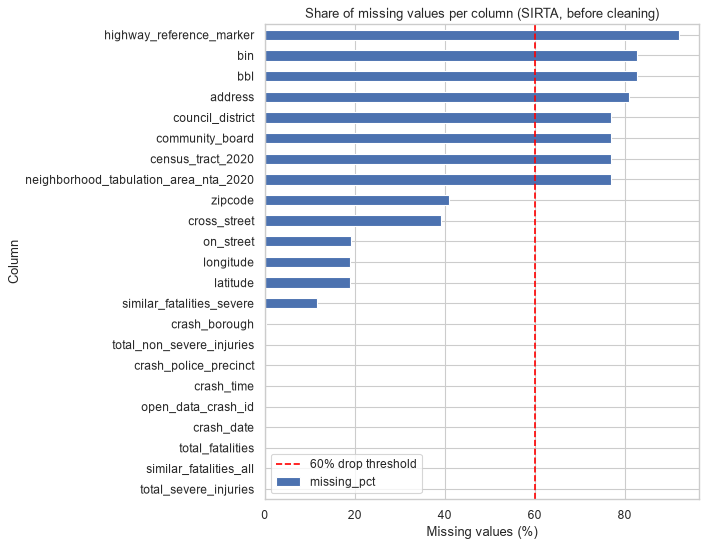

In [6]:
missing = (df.isna().mean() * 100).sort_values(ascending=False).rename("missing_pct").to_frame()
missing["missing_count"] = df.isna().sum()
display(missing)

fig, ax = plt.subplots(figsize=(9, 7))
missing["missing_pct"].sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.axvline(60, color="red", ls="--", label="60% drop threshold")
ax.set_title("Share of missing values per column (SIRTA, before cleaning)")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("Column")
ax.legend()
plt.tight_layout()
plt.show()

### 3.3 Descriptive statistics

In [7]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
display(df[numeric_cols].describe().T)
print("\nCategorical / text columns:")
display(df.select_dtypes(exclude="number").describe().T)

,count,mean,std,min,25%,50%,75%,max
open_data_crash_id,11958.0,4.691295e+06,1.067530e+05,4.491088e+06,4.599792e+06,4.695327e+06,4.782143e+06,4.870224e+06
crash_police_precinct,11958.0,6.777755e+01,3.461355e+01,1.000000e+00,4.200000e+01,6.800000e+01,1.040000e+02,1.230000e+02
total_non_severe_injuries,11958.0,2.713664e-01,8.237919e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.900000e+01
total_severe_injuries,11958.0,1.008363e+00,4.490578e-01,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,7.000000e+00
total_fatalities,11958.0,8.153537e-02,2.928582e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,5.000000e+00
latitude,9683.0,4.073118e+01,8.330138e-02,4.049967e+01,4.066810e+01,4.072798e+01,4.080153e+01,4.091247e+01
longitude,9683.0,-7.392096e+01,8.112754e-02,-7.424857e+01,-7.396770e+01,-7.392297e+01,-7.387535e+01,-7.370060e+01
zipcode,7071.0,1.082461e+04,5.424501e+02,1.000000e+04,1.045100e+04,1.120500e+04,1.123500e+04,1.169400e+04
similar_fatalities_severe,10565.0,9.522007e-02,4.209814e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,9.000000e+00
similar_fatalities_all,11958.0,1.545827e+00,6.014259e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,2.960000e+02



Categorical / text columns:


,count,unique,top,freq
crash_date,11958,1460,2022-05-21T00:00:00.000,22
crash_time,11958,1659,00:00,163
crash_borough,11922,5,Brooklyn,3557
on_street,9676,2717,BROADWAY,155
cross_street,7261,3107,BROADWAY,74
address,2268,2220,101 EAST DRIVE,3
highway_reference_marker,958,760,907LX4M12071,5
neighborhood_tabulation_area_nta_2020,2756,221,MN0502,62


### 3.4 Duplicates

In [8]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated CollisionIDs:", df.duplicated(subset=[COL['collision_id']]).sum())

Fully duplicated rows: 0
Duplicated CollisionIDs: 0


### 3.5 Inconsistencies in key fields
We inspect the categorical/geographic fields we plan to use as integration keys (borough and ZIP) and the date/time fields.

In [9]:
print("Borough values (raw):")
print(df[COL["borough"]].value_counts(dropna=False))
print("\nZIP code - sample of raw values and dtype:", df[COL["zip"]].dtype)
print(df[COL["zip"]].dropna().astype(str).sample(10, random_state=1).tolist())
print("\nCrash date sample:", df[COL["crash_date"]].dropna().astype(str).head(3).tolist())
print("Crash time sample:", df[COL["crash_time"]].dropna().astype(str).head(3).tolist())

Borough values (raw):
crash_borough
Brooklyn         3557
Queens           2974
Manhattan        2448
Bronx            2365
Staten Island     578
NaN                36
Name: count, dtype: int64

ZIP code - sample of raw values and dtype: float64
['10000.0', '10025.0', '10475.0', '11355.0', '11412.0', '11212.0', '10001.0', '10003.0', '11368.0', '11238.0']

Crash date sample: ['2022-01-01T00:00:00.000', '2022-01-01T00:00:00.000', '2022-01-01T00:00:00.000']
Crash time sample: ['01:28', '04:33', '05:55']


### 3.6 Initial plots: what does the data look like?

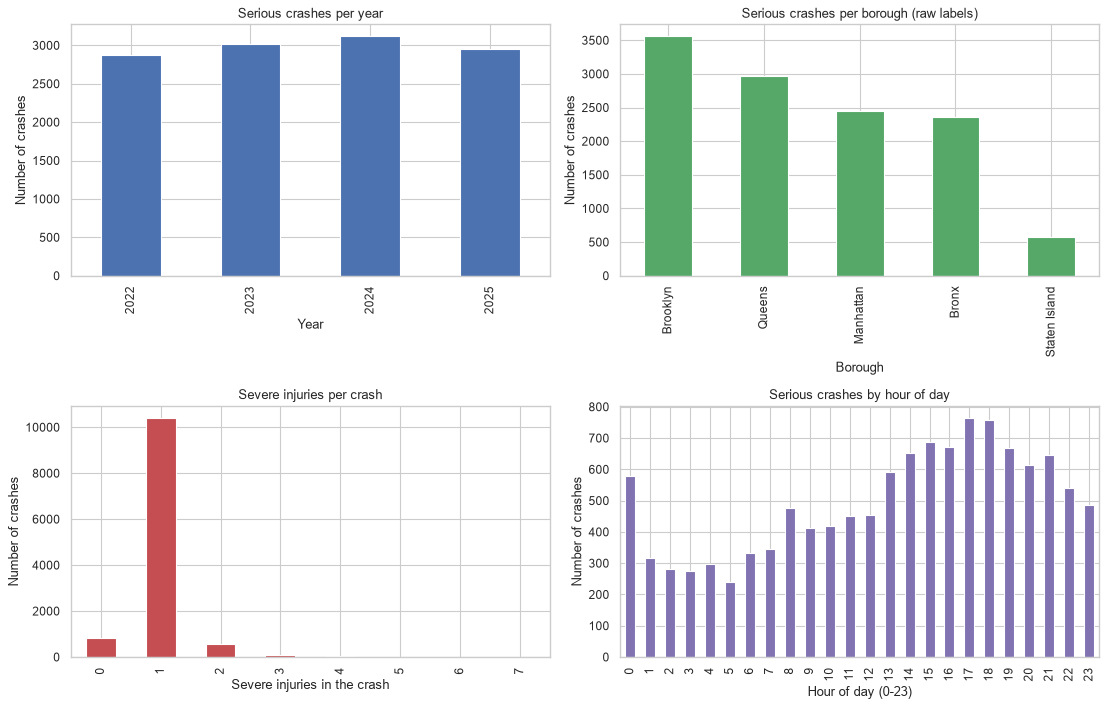

In [10]:
raw_dates = parse_crash_dates(df[COL["crash_date"]])

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# (a) crashes per year
raw_dates.dt.year.value_counts().sort_index().plot.bar(ax=axes[0, 0], color="#4C72B0")
axes[0, 0].set_title("Serious crashes per year")
axes[0, 0].set_xlabel("Year"); axes[0, 0].set_ylabel("Number of crashes")

# (b) crashes per borough
df[COL["borough"]].value_counts().plot.bar(ax=axes[0, 1], color="#55A868")
axes[0, 1].set_title("Serious crashes per borough (raw labels)")
axes[0, 1].set_xlabel("Borough"); axes[0, 1].set_ylabel("Number of crashes")

# (c) distribution of severe injuries per crash
df[COL["severe"]].value_counts().sort_index().head(15).plot.bar(ax=axes[1, 0], color="#C44E52")
axes[1, 0].set_title("Severe injuries per crash")
axes[1, 0].set_xlabel("Severe injuries in the crash"); axes[1, 0].set_ylabel("Number of crashes")

# (d) crashes per hour of day
hours = pd.to_datetime(df[COL["crash_time"]].astype(str), format="%H:%M", errors="coerce").dt.hour
hours.value_counts().sort_index().plot.bar(ax=axes[1, 1], color="#8172B2")
axes[1, 1].set_title("Serious crashes by hour of day")
axes[1, 1].set_xlabel("Hour of day (0-23)"); axes[1, 1].set_ylabel("Number of crashes")

plt.tight_layout()
plt.show()

Inspect the outputs and validation checks for the preceding preparation step.

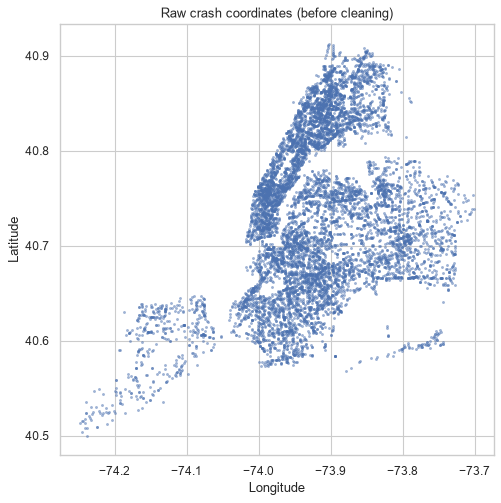

In [11]:
# Geographic sanity check on the raw coordinates (outliers appear as points far from NYC)
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(pd.to_numeric(df[COL["longitude"]], errors="coerce"),
           pd.to_numeric(df[COL["latitude"]], errors="coerce"), s=3, alpha=0.4)
ax.set_title("Raw crash coordinates (before cleaning)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
plt.show()

**EDA take-aways (from the downloaded file: 13,754 rows x 23 columns):**
- **Empty rows:** 444 rows (3.2 %) are completely blank (no Collision ID, date or counts) - removed in 4.0.
- **Missing values:** `highway_reference_marker` (92 %), `address` (81 %), BIN/BBL (80 %), and `community_board`, `council_district`, census tract and NTA (72 %) are too sparse to use. **ZIP is missing in 41 %** and coordinates in 21 % of rows, so the integration key needs repair (4.4).
- **Formats:** dates are `MM/DD/YYYY` text; ZIP is read as float (`11205.0`); borough labels are title-case and ~4 % are missing.
- **Invalid values:** 44 ZIP values equal `10000`, which is a placeholder, not a real NYC ZIP.
- **Time coverage:** 2022-01-01 to 2026-06-30; **2026 is incomplete** (six months).
- **Severity:** most crashes (~84 %) have exactly one severe injury; about 7 % involve a fatality.

## 4. Pre-integration cleaning

Each step states **what** we do, **why**, and **which alternative** we considered.

### 4.0 Remove completely empty rows
The EDA shows about 3% of the rows have **no Collision ID, no date and no severity counts** (every key field is blank). They carry no information, are not crashes, and would all be treated as one "duplicate" in the next step, so we remove them first.

In [12]:
empty_rows = df.isna().all(axis=1)
print(f"Completely empty rows removed: {empty_rows.sum():,}")
df = df.loc[~empty_rows].copy()
missing_id = df[COL["collision_id"]].isna()
print(f"Rows without crash identifier removed: {missing_id.sum():,}")
df = df.loc[~missing_id].copy()

Completely empty rows removed: 0
Rows without crash identifier removed: 0


### 4.1 Remove duplicates
**Decision:** drop exact duplicate rows, then keep one row per `CollisionID`.
**Why:** one row = one crash, so a repeated `CollisionID` double-counts the crash and would inflate the aggregated crash counts that we later correlate with housing.
**Alternative:** keep the most severe duplicate. Because duplicates should be identical copies, keeping the first is equivalent and simpler.

In [13]:
def remove_duplicates(frame, id_col):
    before = len(frame)
    frame = frame.drop_duplicates()
    frame = frame.drop_duplicates(subset=[id_col], keep="first")
    print(f"Removed {before - len(frame):,} duplicate rows ({before:,} -> {len(frame):,}).")
    return frame

df = remove_duplicates(df, COL["collision_id"])

Removed 0 duplicate rows (11,958 -> 11,958).


### 4.2 Standardize formats (dates, strings, categories, geographic identifiers)
- **Dates:** parse `crash_date` to `datetime`; derive `year`, `month`, `day_of_week`. Invalid or impossible dates (unparseable or in the future) are dropped because the year is part of our integration key.
- **Time:** parse `crash_time` (HH:MM) to hour and a `time_of_day` category (night / morning / afternoon / evening).
- **Borough:** strip whitespace and convert to UPPERCASE (`BROOKLYN`, `BRONX`, `MANHATTAN`, `QUEENS`, `STATEN ISLAND`) to match the agreed data contract.
- **ZIP code:** store as a **5-digit string** (never a number, otherwise leading zeros/`.0` break the join).
- **Counts:** injuries/fatalities converted to integers; negative values are invalid.
- **Column names:** lowercase snake_case (done in Section 2).

In [14]:
VALID_BOROUGHS = {"BRONX", "BROOKLYN", "MANHATTAN", "QUEENS", "STATEN ISLAND"}

def standardize_formats(frame, col):
    frame = frame.copy()

    # --- dates and time
    frame["crash_date"] = parse_crash_dates(frame[col["crash_date"]])
    frame["year"] = frame["crash_date"].dt.year
    frame["month"] = frame["crash_date"].dt.month
    frame["day_of_week"] = frame["crash_date"].dt.day_name()
    parsed_time = pd.to_datetime(frame[col["crash_time"]].astype(str).str.strip(), format="%H:%M", errors="coerce")
    frame["crash_hour"] = parsed_time.dt.hour
    frame["time_of_day"] = pd.cut(frame["crash_hour"], bins=[-1, 5, 11, 17, 21, 24],
                                  labels=["night", "morning", "afternoon", "evening", "night_late"])
    frame["time_of_day"] = frame["time_of_day"].astype(str).replace({"night_late": "night", "nan": np.nan})

    # --- borough: trim + uppercase
    frame["borough"] = frame[col["borough"]].astype("string").str.strip().str.upper()

    # --- ZIP: 5-digit string; remove '.0' left by float parsing; non 5-digit values -> NaN
    zip_text = (frame[col["zip"]].astype("string").str.strip()
                .str.replace(r"\.0$", "", regex=True).str.extract(r"^(\d{5})(?:-\d{4})?$", expand=False))
    frame["zip_code"] = zip_text

    # --- numeric columns
    for name in ("severe", "non_severe", "fatalities"):
        frame[f"{name}_count"] = pd.to_numeric(frame[col[name]], errors="coerce")
    frame["latitude"] = pd.to_numeric(frame[col["latitude"]], errors="coerce")
    frame["longitude"] = pd.to_numeric(frame[col["longitude"]], errors="coerce")
    return frame

df = standardize_formats(df, COL)
df[["crash_date", "year", "crash_hour", "time_of_day", "borough", "zip_code",
    "severe_count", "non_severe_count", "fatalities_count"]].head()

,crash_date,year,crash_hour,time_of_day,borough,zip_code,severe_count,non_severe_count,fatalities_count
0,2022-01-01,2022,1,night,BRONX,<NA>,1,1,0
1,2022-01-01,2022,4,night,BRONX,<NA>,1,0,0
2,2022-01-01,2022,5,night,BRONX,<NA>,1,0,0
3,2022-01-01,2022,10,morning,BRONX,<NA>,1,0,0
4,2022-01-01,2022,20,evening,BRONX,<NA>,1,0,0


### 4.3 Check inconsistent data (domain rules)
Rules applied:
1. `crash_date` must be a valid date and **not in the future**.
2. Borough must be one of the 5 NYC boroughs.
3. Injury and fatality counts must be **non-negative**.
4. Coordinates must lie inside a bounding box around New York City (lat 40.45–40.95, lon −74.30 – −73.65); anything else is a data-entry error.
5. ZIP codes must be inside NYC ZIP ranges (100xx–104xx, 110xx–116xx) – this catches typos such as `00000` or ZIPs outside the city.
6. **Borough–ZIP consistency:** a ZIP should map to one borough; where it maps to several we keep the dominant borough (the mode) for the ZIP.

**Decision:** invalid values are set to missing (not silently kept) and then handled by the missing-value strategy in 4.4. Rows without a usable date are dropped (the year is required).

In [15]:
def apply_domain_rules(frame):
    frame = frame.copy()
    report = {}

    # Rule 1: dates
    bad_date = frame["crash_date"].isna() | (frame["crash_date"] > pd.Timestamp.today())
    report["invalid/future date"] = int(bad_date.sum())
    frame = frame.loc[~bad_date].copy()

    # Rule 2: boroughs
    bad_borough = ~frame["borough"].isin(VALID_BOROUGHS) & frame["borough"].notna()
    report["invalid borough label -> NaN"] = int(bad_borough.sum())
    frame.loc[bad_borough, "borough"] = np.nan

    # Rule 3: negative counts
    for name in ("severe_count", "non_severe_count", "fatalities_count"):
        negative = frame[name] < 0
        report[f"negative {name} -> NaN"] = int(negative.sum())
        frame.loc[negative, name] = np.nan

    # Rule 4: coordinates inside the NYC bounding box
    outside = ~(frame["latitude"].between(40.45, 40.95) & frame["longitude"].between(-74.30, -73.65))
    outside &= frame["latitude"].notna() | frame["longitude"].notna()
    report["coordinates outside NYC -> NaN"] = int(outside.sum())
    frame.loc[outside, ["latitude", "longitude"]] = np.nan

    # Rule 5: NYC ZIP ranges
    zip_number = pd.to_numeric(frame["zip_code"], errors="coerce")
    valid_zip = zip_number.between(10001, 10499) | zip_number.between(11001, 11699)
    bad_zip = frame["zip_code"].notna() & ~valid_zip
    report["ZIP outside NYC ranges -> NaN"] = int(bad_zip.sum())
    frame.loc[bad_zip, "zip_code"] = np.nan

    print(pd.Series(report).to_string())
    return frame

df = apply_domain_rules(df)

invalid/future date                  0
invalid borough label -> NaN         0
negative severe_count -> NaN         0
negative non_severe_count -> NaN     0
negative fatalities_count -> NaN     0
coordinates outside NYC -> NaN       0
ZIP outside NYC ranges -> NaN       36


Inspect ZIP/borough label conflicts and use the observed dominant borough consistently.

In [16]:
# Rule 6: borough-ZIP consistency. Use the dominant borough of each ZIP.
zip_to_borough = (df.dropna(subset=["zip_code", "borough"])
                    .groupby("zip_code")["borough"].agg(lambda s: s.mode().iloc[0]))
ambiguous = (df.dropna(subset=["zip_code", "borough"]).groupby("zip_code")["borough"].nunique() > 1).sum()
print(f"ZIP codes appearing in more than one borough label: {ambiguous}")

df["borough"] = df["zip_code"].map(zip_to_borough).fillna(df["borough"])

ZIP codes appearing in more than one borough label: 2


### 4.4 Handle missing values (justify drop vs. impute)

**Column level**
- Columns with **> 60 % missing** and no role in the analysis (e.g. highway reference marker, BIN, BBL, address) are **dropped**. Imputing them would invent information, and they are not needed for ZIP × year aggregation.
- Columns that are always needed (`crash_date`, severity counts) are never imputed; rows missing them are dropped.

**Row level – ZIP code (our integration key)**
- The dictionary says a missing ZIP means *not recorded*. If the crash still has valid coordinates, the ZIP is **recovered from the nearest crash that has a ZIP** (1-nearest-neighbour on latitude/longitude) – but only if that neighbour is very close (≈ 500 m) so we do not assign a wrong ZIP.
- Rows with **no ZIP and no usable coordinates** are **dropped**: without the key they cannot take part in the ZIP × year integration. The number dropped is reported.

**Alternatives considered:** (a) impute ZIP with the most frequent ZIP of the borough – rejected because it would bias counts toward one ZIP; (b) keep rows with missing ZIP and group them as "UNKNOWN" – rejected because they could never be joined to housing data.

**Count columns:** a blank means *not recorded*, not zero, so we never fill missing counts with 0. Rows with a missing severe-injury count are dropped; gaps in the secondary counts (non-severe, fatalities) stay as missing and are skipped by the aggregation.

In [17]:
MISSING_DROP_THRESHOLD = 0.60

def drop_sparse_columns(frame, threshold=MISSING_DROP_THRESHOLD, protect=()):
    share = frame.isna().mean()
    to_drop = [c for c in share[share > threshold].index if c not in protect]
    print("Dropping columns with >60% missing:", to_drop)
    return frame.drop(columns=to_drop)

PROTECTED = ["crash_date", "year", "month", "borough", "zip_code", "latitude", "longitude",
             "severe_count", "non_severe_count", "fatalities_count", "crash_hour", "time_of_day", "day_of_week"]
df = drop_sparse_columns(df, protect=PROTECTED)

Dropping columns with >60% missing: ['address', 'highway_reference_marker', 'community_board', 'council_district', 'bin', 'bbl', 'census_tract_2020', 'neighborhood_tabulation_area_nta_2020']


Recover only nearby missing ZIPs, report remaining missingness and drop unusable integration keys.

In [18]:
def impute_zip_from_nearest_crash(frame, max_distance_deg=0.005):
    """Fill a missing ZIP with the ZIP of the nearest crash (same file) that has one.
    0.005 degrees is roughly 500 m in NYC; farther neighbours are not trusted."""
    frame = frame.copy()
    known = frame.dropna(subset=["zip_code", "latitude", "longitude"])
    target = frame[frame["zip_code"].isna() & frame["latitude"].notna() & frame["longitude"].notna()]
    print(f"Missing ZIP: {frame['zip_code'].isna().sum():,} | recoverable via coordinates: {len(target):,}")
    if len(target) == 0 or len(known) == 0:
        return frame, 0
    nn = NearestNeighbors(n_neighbors=1).fit(known[["latitude", "longitude"]])
    distance, index = nn.kneighbors(target[["latitude", "longitude"]])
    close_enough = distance[:, 0] <= max_distance_deg
    filled_index = target.index[close_enough]
    frame.loc[filled_index, "zip_code"] = known["zip_code"].to_numpy()[index[close_enough, 0]]
    # borough follows the (new) ZIP
    frame.loc[filled_index, "borough"] = frame.loc[filled_index, "zip_code"].map(zip_to_borough).fillna(frame.loc[filled_index, "borough"])
    print(f"ZIP imputed for {len(filled_index):,} rows.")
    return frame, len(filled_index)

df, n_zip_imputed = impute_zip_from_nearest_crash(df)

# Drop rows that still lack the integration key or the core measures
before = len(df)
df = df.dropna(subset=["zip_code", "severe_count"]).copy()
print(f"Dropped {before - len(df):,} rows without ZIP or severe-injury count ({before:,} -> {len(df):,}).")

# Remaining numeric gaps in the secondary counts: blank = 'not recorded', so keep them as NaN (not 0)
# and let the aggregation skip them; they are reported rather than invented.
print(df[["non_severe_count", "fatalities_count", "borough", "crash_hour"]].isna().sum())
df = df.dropna(subset=["borough"]).copy()

Missing ZIP: 4,923 | recoverable via coordinates: 3,814


ZIP imputed for 3,496 rows.


Dropped 1,427 rows without ZIP or severe-injury count (11,958 -> 10,531).
non_severe_count    0
fatalities_count    0
borough             0
crash_hour          0
dtype: int64


### 4.5 Restrict to the common time window
To make the two datasets comparable we keep only years shared with the housing dataset. The SIRTA file runs from 2022-01-01 to **2026-06-30**: 2022-2025 are complete years, while **2026 covers only six months**, so comparing its yearly totals with full years would look like a (false) drop in crashes. By default we therefore keep **2022-2025**; change `YEAR_MIN`/`YEAR_MAX` in Section 2 if the team agrees on another window. DOT's severity classification can also lag, which is documented as a limitation.

In [19]:
if YEAR_MIN is not None:
    df = df[df["year"] >= YEAR_MIN]
if YEAR_MAX is not None:
    df = df[df["year"] <= YEAR_MAX]
df["year"] = df["year"].astype(int)
print("Years kept:", sorted(df["year"].unique()), "| rows:", len(df))

Years kept: [np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)] | rows: 10531


### 4.6 Outlier detection and treatment
Two complementary methods:
1. **Domain rules** (already applied in 4.3): impossible coordinates, dates, negative counts.
2. **IQR rule** on the severity counts per crash: values above `Q3 + 1.5·IQR` are *flagged*.

**Decision:** statistical outliers in severity counts are **flagged but kept**. A crash with many severe injuries is rare but **real** (e.g. a multi-victim crash) and is exactly what a safety analysis should capture; deleting it would hide the most important events. The `is_outlier_severe` flag lets the website and analysis exclude them if needed. For the ZIP × year aggregates (Section 6) we repeat the IQR check and flag unusually high-crash ZIPs.
**Alternative considered:** winsorizing/capping – rejected because it would artificially reduce real severity.

**Note on the IQR result:** about 84 % of crashes have exactly **1** severe injury, so Q1 = Q3 = 1 and the IQR is 0: the bounds collapse to [1, 1] and *any* crash with 2+ severe injuries is flagged (~6 %). This is expected for a heavily concentrated count variable and the flag is only informative ("multi-victim crash"), which is another reason we keep and flag instead of delete. The more meaningful IQR check is the one on ZIP × year crash counts in Section 6.

IQR bounds for severe injuries per crash: [1.0, 1.0] -> 614 flagged crashes (5.83%).


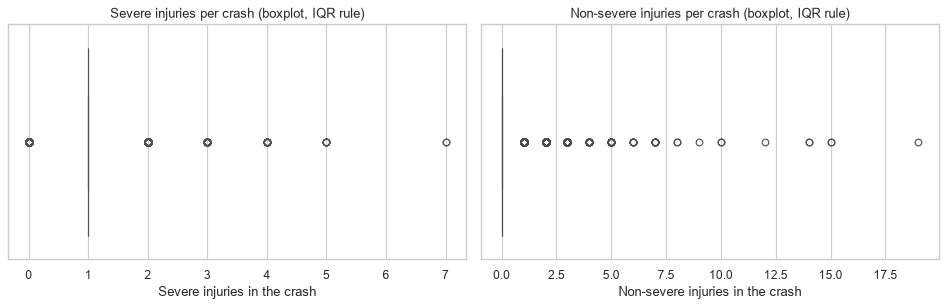

In [20]:
def iqr_bounds(series, factor=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    spread = q3 - q1
    return q1 - factor * spread, q3 + factor * spread

lower, upper = iqr_bounds(df["severe_count"])
df["is_outlier_severe"] = df["severe_count"] > upper
print(f"IQR bounds for severe injuries per crash: [{lower:.1f}, {upper:.1f}] -> "
      f"{df['is_outlier_severe'].sum():,} flagged crashes ({df['is_outlier_severe'].mean():.2%}).")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df["severe_count"], ax=axes[0], color="#C44E52")
axes[0].set_title("Severe injuries per crash (boxplot, IQR rule)")
axes[0].set_xlabel("Severe injuries in the crash")
sns.boxplot(x=df["non_severe_count"].dropna(), ax=axes[1], color="#4C72B0")
axes[1].set_title("Non-severe injuries per crash (boxplot, IQR rule)")
axes[1].set_xlabel("Non-severe injuries in the crash")
plt.tight_layout()
plt.show()

## 5. Validation of the cleaning (before vs. after)
These checks and plots demonstrate that the cleaning did what we intended.

In [21]:
checks = pd.DataFrame({
    "rows": [len(df_raw), len(df)],
    "missing_zip": [df_raw[[c for c in df_raw.columns if 'zip' in c.lower()][0]].isna().sum(), df["zip_code"].isna().sum()],
    "duplicated_collision_ids": [df_raw.duplicated(subset=[COL['collision_id']]).sum(), df.duplicated(subset=[COL['collision_id']]).sum()],
}, index=["raw", "clean"])
display(checks)

assert df["zip_code"].str.fullmatch(r"\d{5}").all(), "ZIP must be a 5-digit string"
assert df["borough"].isin(VALID_BOROUGHS).all(), "borough labels must be standardized"
assert (df[["severe_count"]] >= 0).all().all(), "negative counts found"
assert df["latitude"].dropna().between(40.45, 40.95).all()
print("All validation assertions passed.")

,rows,missing_zip,duplicated_collision_ids
raw,11958,4887,0
clean,10531,0,0


All validation assertions passed.


Visualize the distributions or validation results for the preceding analysis step.

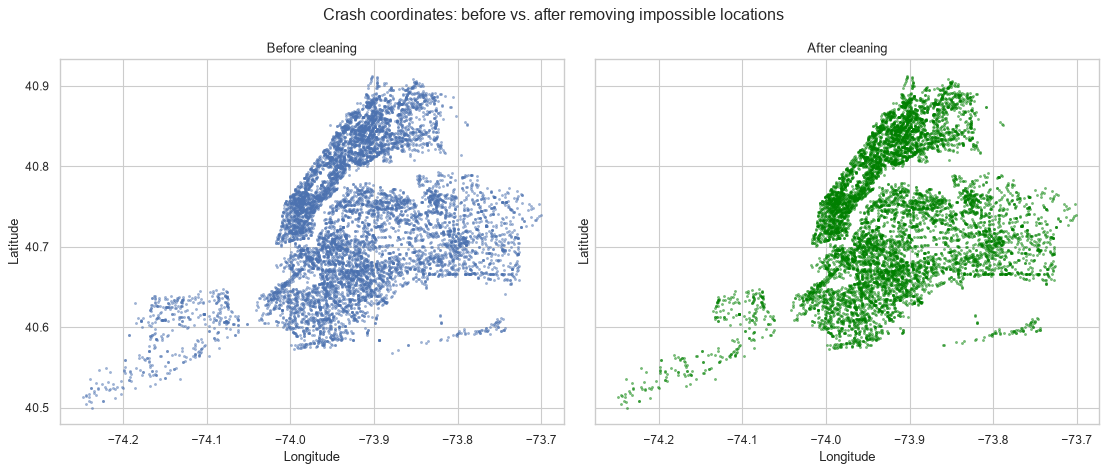

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
axes[0].scatter(pd.to_numeric(df_raw[[c for c in df_raw.columns if 'longitude' in c.lower()][0]], errors="coerce"),
                pd.to_numeric(df_raw[[c for c in df_raw.columns if 'latitude' in c.lower()][0]], errors="coerce"), s=3, alpha=0.4)
axes[0].set_title("Before cleaning")
axes[1].scatter(df["longitude"], df["latitude"], s=3, alpha=0.4, color="green")
axes[1].set_title("After cleaning")
for ax in axes:
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
fig.suptitle("Crash coordinates: before vs. after removing impossible locations")
plt.tight_layout()
plt.show()

Summarize retained crash counts by standardized borough.

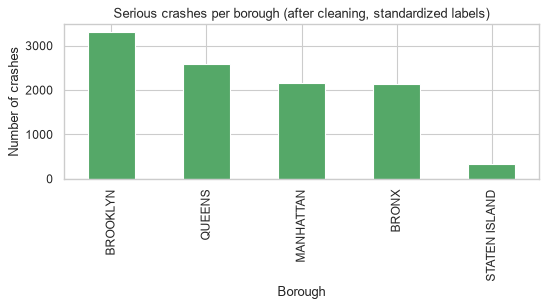

In [23]:
borough_after = df["borough"].value_counts()
fig, ax = plt.subplots(figsize=(7, 4))
borough_after.plot.bar(ax=ax, color="#55A868")
ax.set_title("Serious crashes per borough (after cleaning, standardized labels)")
ax.set_xlabel("Borough"); ax.set_ylabel("Number of crashes")
plt.tight_layout(); plt.show()

## 6. ZIP code x year aggregation
Count crashes and sum recorded injuries/deaths. Secondary counts remain unknown if an entire group is missing; missing is not zero. Nighttime means hours 00-05 and 22-23. **Unknown time is excluded from the share's denominator**, not counted as daytime. Export nighttime numerators/known-time denominators so later aggregation can weight shares correctly.

ZIP recovery is approximate and reported above; broad numeric ZIP screening is not a USPS boundary validation. These are counts in the retained ZIP-known subset, not a census of every NYC crash.

In [24]:
def aggregate_to_zip_year(frame):
    frame = frame.copy()
    frame["is_fatal_crash"] = frame["fatalities_count"].gt(0).astype(float).where(frame["fatalities_count"].notna())
    frame["is_night"] = frame["time_of_day"].eq("night").astype(float).where(frame["crash_hour"].notna())
    aggregated = frame.groupby(["zip_code", "year"]).agg(
        borough=("borough", lambda s: s.mode().iloc[0]),
        crash_count=("severe_count", "size"),
        severe_injuries_total=("severe_count", lambda s: s.sum(min_count=1)),
        non_severe_injuries_total=("non_severe_count", lambda s: s.sum(min_count=1)),
        fatalities_total=("fatalities_count", lambda s: s.sum(min_count=1)),
        fatal_crash_count=("is_fatal_crash", lambda s: s.sum(min_count=1)),
        severe_per_crash=("severe_count", "mean"),
        night_crash_share=("is_night", "mean"),
        night_crash_count=("is_night", "sum"),
        crashes_with_known_time=("is_night", "count"),
        avg_latitude=("latitude", "mean"),
        avg_longitude=("longitude", "mean"),
    ).reset_index()
    low, high = iqr_bounds(aggregated["crash_count"])
    aggregated["is_outlier_zip_year"] = aggregated["crash_count"] > high
    aggregated["zip_code"] = aggregated["zip_code"].astype(str)
    return aggregated

df_transport_agg = aggregate_to_zip_year(df)
print(df_transport_agg.shape)
display(df_transport_agg.head())

(702, 15)


,zip_code,year,borough,crash_count,severe_injuries_total,non_severe_injuries_total,fatalities_total,fatal_crash_count,severe_per_crash,night_crash_share,night_crash_count,crashes_with_known_time,avg_latitude,avg_longitude,is_outlier_zip_year
0,10001,2022,MANHATTAN,17,18.0,4.0,1.0,1.0,1.058824,0.176471,3.0,17,40.750403,-73.995298,False
1,10001,2023,MANHATTAN,26,24.0,9.0,2.0,2.0,0.923077,0.307692,8.0,26,40.751362,-73.996973,False
2,10001,2024,MANHATTAN,21,24.0,18.0,0.0,0.0,1.142857,0.333333,7.0,21,40.750665,-73.994919,False
3,10001,2025,MANHATTAN,18,17.0,3.0,1.0,1.0,0.944444,0.222222,4.0,18,40.750087,-73.995602,False
4,10002,2022,MANHATTAN,23,28.0,4.0,2.0,2.0,1.217391,0.652174,15.0,23,40.716705,-73.984744,False


Inspect the outputs and validation checks for the preceding preparation step.

In [25]:
# Final quality checks on the aggregated table
assert not df_transport_agg.duplicated(subset=["zip_code", "year"]).any(), "key must be unique"
assert pd.api.types.is_string_dtype(df_transport_agg["zip_code"]), "ZIP must be text"
print(df_transport_agg.isna().sum()[lambda s: s > 0])
display(df_transport_agg.describe().T)

avg_latitude     3
avg_longitude    3
dtype: int64


,count,mean,std,min,25%,50%,75%,max
year,702.0,2023.514245,1.116187,2022.000000,2023.000000,2024.000000,2025.000000,2025.000000
crash_count,702.0,15.001425,10.144955,1.000000,7.000000,13.000000,22.000000,48.000000
severe_injuries_total,702.0,15.341880,10.618797,0.000000,7.000000,13.000000,22.000000,51.000000
non_severe_injuries_total,702.0,3.898860,4.328161,0.000000,1.000000,3.000000,6.000000,35.000000
fatalities_total,702.0,0.915954,1.156783,0.000000,0.000000,1.000000,1.000000,8.000000
fatal_crash_count,702.0,0.877493,1.098218,0.000000,0.000000,1.000000,1.000000,8.000000
severe_per_crash,702.0,1.015664,0.152715,0.000000,0.961538,1.000000,1.062500,2.000000
night_crash_share,702.0,0.242675,0.182533,0.000000,0.130435,0.230769,0.333333,1.000000
night_crash_count,702.0,3.690883,3.185631,0.000000,1.000000,3.000000,5.000000,17.000000
crashes_with_known_time,702.0,15.001425,10.144955,1.000000,7.000000,13.000000,22.000000,48.000000


Export the validated row-level and ZIP-year tables to the shared clean-data directory.

In [26]:
EXPORT_COLUMNS = [COL["collision_id"], "crash_date", "year", "month", "day_of_week", "crash_hour", "time_of_day",
                  "borough", "zip_code", "latitude", "longitude", "severe_count", "non_severe_count",
                  "fatalities_count", "is_outlier_severe", "on_street", "cross_street", COL["precinct"]]
df_clean_export = df[[c for c in EXPORT_COLUMNS if c in df.columns]].copy()
df_clean_export = df_clean_export.rename(columns={COL["collision_id"]: "collision_id", COL["precinct"]: "precinct"})
df_clean_export.to_csv(OUTPUT_ROW_LEVEL, index=False)
df_transport_agg.to_csv(OUTPUT_AGGREGATED, index=False)
print(f"Saved {OUTPUT_ROW_LEVEL} ({len(df_clean_export):,} rows) and {OUTPUT_AGGREGATED} ({len(df_transport_agg):,} rows).")

Saved C:\Users\t-pnassef\OneDrive - Microsoft\Desktop\nyc-housing-transport\data\clean\transport_clean_row_level.csv (10,531 rows) and C:\Users\t-pnassef\OneDrive - Microsoft\Desktop\nyc-housing-transport\data\clean\transport_clean.csv (702 rows).


## 7. Two research questions and visualizations
Run Member 3 first to refresh the integrated data. Read the actual shared path and agreed columns; there are no placeholder metrics.

**RQ1:** Across ZIP-years, how is filing activity associated with the number of people seriously injured in recorded crashes? A scatter plot shows counts, not individual risk.

**RQ2:** Does the observed nighttime crash share differ across filing-volume groups within each borough? A heatmap uses nighttime counts divided by **known-time crash counts**, not an unweighted mean of ZIP percentages. Filing groups are descriptive quartiles, not causal treatments.

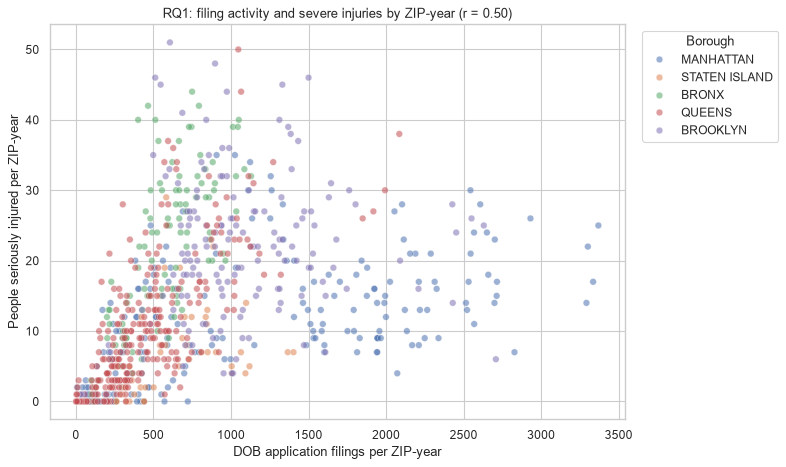

**RQ1 finding:** pooled Pearson r = **0.50**. This descriptive association may reflect ZIP size/traffic; repeated ZIP-years are not independent, so no independence-based p-value or causal claim is made.

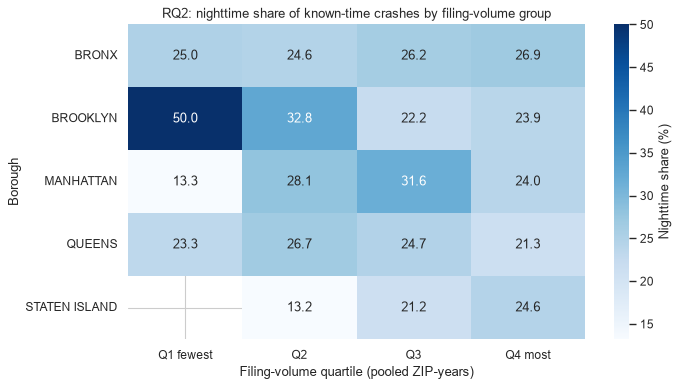

**RQ2 finding:** observed shares range from **13.2% to 50.0%** across borough/quartile cells with known-time crashes. Blank cells have no usable denominator. Quartiles mix years and differently sized ZIPs; the pattern is not evidence that development changes nighttime risk.

night_crash_count  crashes_with_known_time  \
borough       filing_quartile                                               
BRONX         Q1 fewest                       11                       44   
              Q2                             122                      495   
              Q3                             345                     1319   
              Q4 most                         73                      271   
BROOKLYN      Q1 fewest                        2                        4   
              Q2                              45                      137   
              Q3                             289                     1300   
              Q4 most                        448                     1872   
MANHATTAN     Q1 fewest                        6                       45   
              Q2                              94                      334   
              Q3                              87                      275   
              Q4 most                        361                     1505   
QUEENS        Q1 fewest                       31                      133   
              Q2                             254                      953   
              Q3                             230                      930   
              Q4 most                        123                      578   
STATEN ISLAND Q2                               7                       53   
              Q3                              47                      222   
              Q4 most                         14                       57   

                               night_share  
borough       filing_quartile               
BRONX         Q1 fewest           0.250000  
              Q2                  0.246465  
              Q3                  0.261562  
              Q4 most             0.269373  
BROOKLYN      Q1 fewest           0.500000  
              Q2                  0.328467  
              Q3                  0.222308  
              Q4 most             0.239316  
MANHATTAN     Q1 fewest           0.133333  
              Q2                  0.281437  
              Q3                  0.316364  
              Q4 most             0.239867  
QUEENS        Q1 fewest           0.233083  
              Q2                  0.266527  
              Q3                  0.247312  
              Q4 most             0.212803  
STATEN ISLAND Q2                  0.132075  
              Q3                  0.211712  
              Q4 most             0.245614

In [27]:
df_merged = pd.read_csv(CLEAN_DIR / "integrated_dataset.csv", dtype={"zip_code": str})
analysis_transport = df_merged.loc[df_merged["has_housing_data"] & df_merged["filing_count"].notna()].copy()
assert not analysis_transport.empty, "No integrated housing rows for analysis."
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=analysis_transport, x="filing_count", y="severe_injuries_total",
                hue="borough", alpha=0.55, ax=ax)
transport_r = analysis_transport["filing_count"].corr(analysis_transport["severe_injuries_total"])
ax.set(title=f"RQ1: filing activity and severe injuries by ZIP-year (r = {transport_r:.2f})",
       xlabel="DOB application filings per ZIP-year", ylabel="People seriously injured per ZIP-year")
ax.legend(title="Borough", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
display(Markdown(f"**RQ1 finding:** pooled Pearson r = **{transport_r:.2f}**. "
                 "This descriptive association may reflect ZIP size/traffic; repeated ZIP-years are not independent, "
                 "so no independence-based p-value or causal claim is made."))

analysis_transport["filing_quartile"] = pd.qcut(
    analysis_transport["filing_count"].rank(method="min", pct=True),
    [0, .25, .5, .75, 1], labels=["Q1 fewest", "Q2", "Q3", "Q4 most"])
night_summary = analysis_transport.groupby(["borough", "filing_quartile"], observed=True)[
    ["night_crash_count", "crashes_with_known_time"]].sum()
night_summary["night_share"] = night_summary["night_crash_count"] / night_summary["crashes_with_known_time"].replace(0, np.nan)
pivot = night_summary["night_share"].unstack()
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(pivot * 100, annot=True, fmt=".1f", cmap="Blues", ax=ax, cbar_kws={"label": "Nighttime share (%)"})
ax.set(title="RQ2: nighttime share of known-time crashes by filing-volume group",
       xlabel="Filing-volume quartile (pooled ZIP-years)", ylabel="Borough")
plt.tight_layout()
plt.show()
valid_night = night_summary["night_share"].dropna()
assert not valid_night.empty
display(Markdown(f"**RQ2 finding:** observed shares range from **{valid_night.min():.1%} to {valid_night.max():.1%}** "
                 "across borough/quartile cells with known-time crashes. Blank cells have no usable denominator. "
                 "Quartiles mix years and differently sized ZIPs; the pattern is not evidence that development changes nighttime risk."))
display(night_summary)

### Interpretation and limitations
The findings above are calculated from the regenerated data. Serious crashes are a selected subset; missing ZIPs/time affect coverage; nearest-neighbor ZIP recovery is approximate; population and traffic exposure are absent; severity classifications can lag. Counts and nighttime shares do not measure residents' individual risk, and correlation is not causation.

## 8. Prompts used, links, and contribution

### 8.1 Dataset links
- **Transportation (T4, SIRTA):** https://data.cityofnewyork.us/Transportation/Serious-Injury-Response-Tracking-Analysis-Program-/xeqp-qz8h
- **Housing (Member 1):** [DOB NOW Build Job Application Filings](https://data.cityofnewyork.us/Housing-Development/DOB-NOW-Build-Job-Application-Filings/w9ak-ipjd)
- **Dataset catalog / project description:** provided by the course (Dr. Nada Sharaf, TAs).

### 8.2 Prompts used (required by the project)
Record **every** prompt used in this part, with the step it supported:

| # | Step | Prompt (summary) |
|---|---|---|
| 1 | Planning | Asked an AI assistant to review the 5-member task division and timeline against the project requirements. |
| 2 | Dataset choice | Asked which transportation dataset from the catalog best integrates with a housing dataset (ZIP × year); chose T4/SIRTA (`xeqp-qz8h`). |
| 3 | Loading | Asked for code to download the dataset with the NYC Open Data API (`$limit`, `$order`) and a fallback to a local CSV. |
| 4 | Notebook | Asked an AI assistant to build the Member 2 notebook (overview, EDA, pre-integration cleaning, aggregation, research questions) using the SIRTA data dictionary, satisfying every grading requirement. |

*(Add any later prompts here, e.g. for debugging or chart design.)*

### 8.3 Member 2 contribution (copy to the README)
- Selected and documented the transportation dataset (SIRTA, T4) and justified the choice.
- Performed EDA (structure, missing values, duplicates, inconsistencies, distributions).
- Pre-integration cleaning: duplicates, format standardization (dates, borough, 5-digit ZIP), domain-rule checks, ZIP recovery from coordinates, outlier flagging (IQR), validation plots.
- Aggregated the data to ZIP × year and delivered `transport_clean.csv` per the data contract.
- Executed 2 research questions and 2 visualizations (Section 7).